In [ ]:
!pip install librosa hmmlearn seaborn joblib audioread

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 1.6 MB/s eta 0:00:00


In [ ]:
import librosa
import librosa.display

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mode
from hmmlearn.hmm import CategoricalHMM

import joblib

from google.colab import files

In [ ]:
uploaded = files.upload()

Saving bhairavi9 to bhairavi9
Saving bhairavi8.wav to bhairavi8.wav
Saving bhairavi7.wav to bhairavi7.wav
Saving bhairavi6.wav to bhairavi6.wav
Saving Bhairavi5.wav to Bhairavi5.wav
Saving Bhairavi4.wav to Bhairavi4.wav
Saving Bhairavi3.wav to Bhairavi3.wav
Saving Bhairavi2.wav to Bhairavi2.wav
Saving Bhairavi1.wav to Bhairavi1.wav


In [ ]:
print(list(uploaded.keys()))

['bhairavi9', 'bhairavi8.wav', 'bhairavi7.wav', 'bhairavi6.wav', 'Bhairavi5.wav', 'Bhairavi4.wav', 'Bhairavi3.wav', 'Bhairavi2.wav', 'Bhairavi1.wav']


In [ ]:
all_swaras = [
    "S",
    "r",
    "R",
    "g",
    "G",
    "M",
    "m",
    "P",
    "d",
    "D",
    "n",
    "N"
]

swara_to_num = {
    "S":0,
    "r":1,
    "R":2,
    "g":3,
    "G":4,
    "M":5,
    "m":6,
    "P":7,
    "d":8,
    "D":9,
    "n":10,
    "N":11
}

num_to_swara = {
    value:key
    for key,value in swara_to_num.items()
}

In [ ]:
def get_swara_sequence_bhairavi(audio_path):
    try:
        y, sr = librosa.load(audio_path)
        f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
        valid_f0 = f0[~np.isnan(f0)]

        if len(valid_f0) == 0:
            return []

        # Use mode to find Tonic
        tonic_sa = float(scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0])
        # librosa.hz_to_svara_h returns abbreviated svara names by default (e.g., 'S', 'r')
        swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

        # Define allowed swaras for Raag Bhairavi: S, komal r, komal g, M, P, komal d, komal n
        # In `all_swaras`, these are represented as 'S', 'r', 'g', 'M', 'P', 'd', 'n'
        bhairavi_allowed = ['S', 'R', 'G', 'M', 'P', 'D', 'N']

        clean = []
        for s in swaras:
            # Filter to include only the allowed Bhairavi swaras
            if s in bhairavi_allowed:
                clean.append(s)

        # Compress consecutive duplicates to capture macro-movement step
        compressed = []
        if clean:
            compressed.append(clean[0])
            for i in range(1, len(clean)):
                if clean[i] != clean[i-1]:
                    compressed.append(clean[i])
        return compressed
    except Exception as e:
        print(f"Skipping {audio_path} due to error: {e}")
        return []

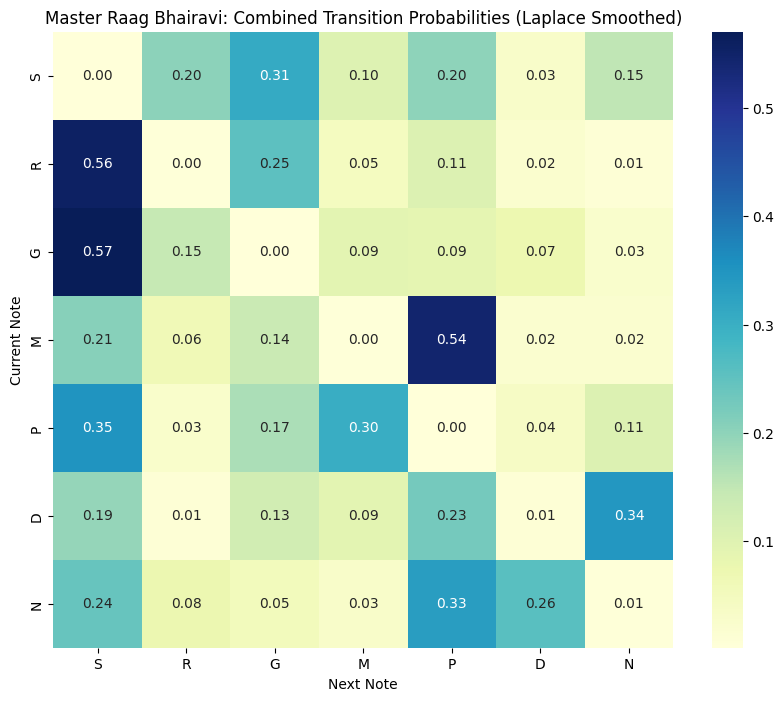

Total processed files: 15
Sample sequence lengths: [261, 104, 98, 137, 94, 169, 85, 195, 99, 128, 198, 85, 126, 170, 88]


In [ ]:
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns
import os # Import the os module

# Define the allowed swaras for Raag Bhairavi
bhairavi_allowed = ['S', 'R', 'G', 'M', 'P', 'D', 'N'] # S, komal r, komal g, M, P, komal d, komal n

master_counts = pd.DataFrame(0, index=bhairavi_allowed, columns=bhairavi_allowed)

# Collect and process all compressed sequences for Bhairavi
all_sequences = []

# Iterate through files in the current directory and filter for 'bhairavi' files
for filename in os.listdir('/content/'):
    if 'bhairavi' in filename.lower() and (filename.endswith('.wav') or filename.endswith('.mp3')):
        # Prepend '/content/' to ensure correct path, as librosa.load expects a path
        audio_path = os.path.join('/content/', filename)
        seq = get_swara_sequence_bhairavi(audio_path)
        all_sequences.append(seq)

# Aggregate counts across all files
for seq in all_sequences:
    for i in range(len(seq) - 1):
        current_n = seq[i]
        next_n = seq[i+1]
        if current_n in master_counts.index and next_n in master_counts.columns:
            master_counts.loc[current_n, next_n] += 1

# --- THE SMOOTHING STEP ---
# Adds 1 to avoid absolute 0% probabilities (Laplace Smoothing)
smoothed_counts = master_counts + 1

# Normalize rows to build the Master Markov Transition Matrix
combined_transition_matrix = smoothed_counts.div(smoothed_counts.sum(axis=1), axis=0)

# --- VISUALIZE THE COMBINED MATRIX ---
plt.figure(figsize=(10, 8))
sns.heatmap(combined_transition_matrix, annot=True, cmap="YlGnBu", fmt=".2f",
            xticklabels=bhairavi_allowed, yticklabels=bhairavi_allowed)
plt.title("Master Raag Bhairavi: Combined Transition Probabilities (Laplace Smoothed)")
plt.xlabel("Next Note")
plt.ylabel("Current Note")
plt.show()

# Print debug confirmation to check sequence capture metrics
print(f"Total processed files: {len(all_sequences)}")
print("Sample sequence lengths:", [len(s) for s in all_sequences])

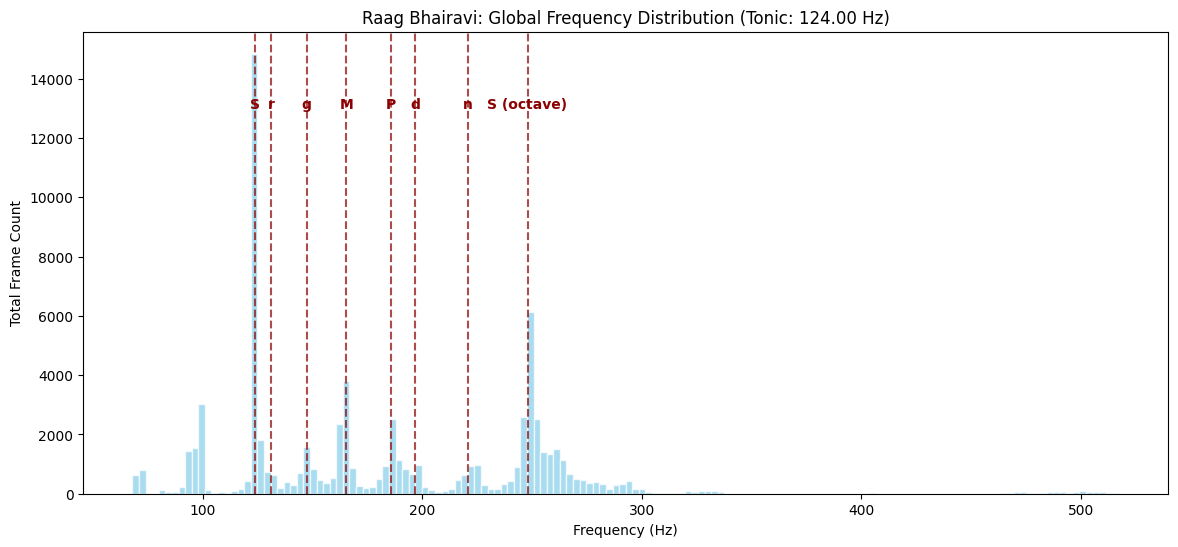

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats
import librosa
import os

# Initialize lists to store f0 for all Bhairavi audio files
all_f0_lists_bhairavi = []

# Iterate through files in the current directory and filter for 'bhairavi' files
for filename in os.listdir('/content/'):
    if 'bhairavi' in filename.lower() and (filename.endswith('.wav') or filename.endswith('.mp3')):
        audio_path = os.path.join('/content/', filename)
        try:
            y, sr = librosa.load(audio_path)
            f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
            all_f0_lists_bhairavi.append(f0)
        except Exception as e:
            print(f"Skipping {audio_path} due to error: {e}")

# 1. Flatten all valid pitches into one array for Bhairavi
all_valid_f0_bhairavi = np.concatenate([f[~np.isnan(f)] for f in all_f0_lists_bhairavi])

# 2. CALCULATE GLOBAL TONIC for Bhairavi
# Using scipy.stats.mode with keepdims=True to handle potential multiple modes
if all_valid_f0_bhairavi.size > 0:
    global_tonic_bhairavi = float(scipy.stats.mode(np.round(all_valid_f0_bhairavi), keepdims=True).mode[0])
else:
    global_tonic_bhairavi = None
    print("No valid f0 data found for Bhairavi files to determine tonic.")

# Define swara ratios for Raag Bhairavi based on 12-TET intervals from a tonic
# Sa = 1.0
# komal r (Re) = 2^(1/12) = 1.05946
# komal g (Ga) = 2^(3/12) = 1.18921
# M (Ma) = 2^(5/12) = 1.33484
# P (Pa) = 2^(7/12) = 1.49831
# komal d (Dha) = 2^(8/12) = 1.58740
# komal n (Ni) = 2^(10/12) = 1.78180
# Sa' (Octave) = 2.0
bhairavi_swara_ratios = {
    'S': 1.0,
    'r': 2**(1/12),
    'g': 2**(3/12),
    'M': 2**(5/12),
    'P': 2**(7/12),
    'd': 2**(8/12),
    'n': 2**(10/12),
    'S (octave)': 2.0
}

if global_tonic_bhairavi is not None:
    plt.figure(figsize=(14, 6))
    counts, bins, patches = plt.hist(all_valid_f0_bhairavi, bins=150, color='skyblue', alpha=0.7, edgecolor='white')

    # Plot swara lines for Bhairavi
    for name, ratio in bhairavi_swara_ratios.items():
        freq = global_tonic_bhairavi * ratio
        plt.axvline(x=freq, color='darkred', linestyle='--', alpha=0.7)
        plt.text(freq, np.max(counts) * 0.9, name, color='darkred', fontweight='bold', ha='center', va='top')

    plt.title(f"Raag Bhairavi: Global Frequency Distribution (Tonic: {global_tonic_bhairavi:.2f} Hz)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Total Frame Count")
    plt.show()
else:
    print("Could not generate plot as no global tonic was determined.")

### Combined Pitch Contour for Raag Bhairavi

This plot visualizes the fundamental frequency (f0) contours of all processed Raag Bhairavi audio files, concatenated sequentially. The horizontal dashed lines represent the theoretical frequencies of the Bhairavi swaras (notes) relative to the calculated global tonic, providing a visual reference for the melodic movement.

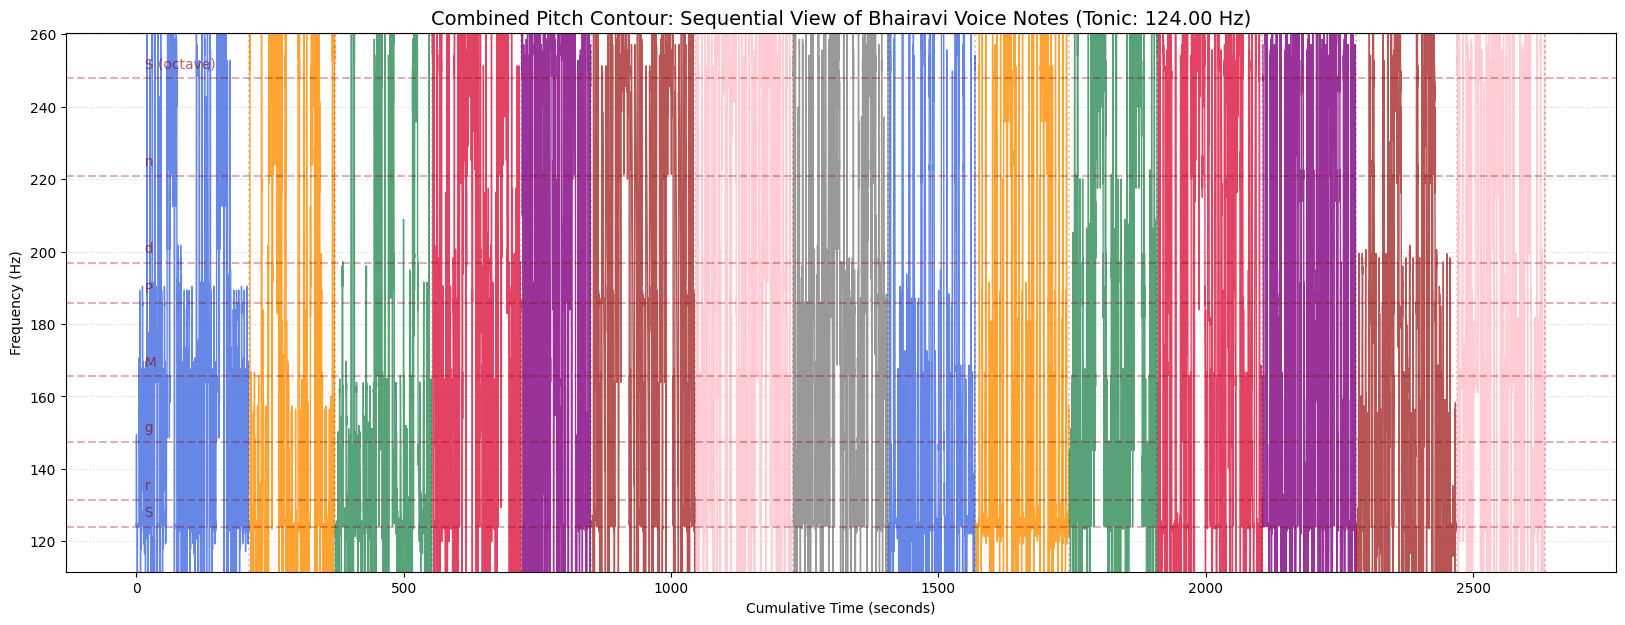

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import librosa
import os

# Initialize lists to store f0 and times for all Bhairavi audio files
all_f0_lists_bhairavi_plot = []
all_times_lists_bhairavi_plot = []

# Iterate through files in the current directory and filter for 'bhairavi' files
for filename in os.listdir('/content/'):
    if 'bhairavi' in filename.lower() and (filename.endswith('.wav') or filename.endswith('.mp3')):
        audio_path = os.path.join('/content/', filename)
        try:
            y, sr = librosa.load(audio_path)
            f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
            times = librosa.times_like(f0, sr=sr)
            all_f0_lists_bhairavi_plot.append(f0)
            all_times_lists_bhairavi_plot.append(times)
        except Exception as e:
            print(f"Skipping {audio_path} due to error: {e}")

plt.figure(figsize=(20, 7))
current_time_offset = 0
colors = ['royalblue', 'darkorange', 'seagreen', 'crimson', 'purple', 'brown', 'pink', 'gray'] # Cycling colors for clarity

for i, (f0_single, times_single) in enumerate(zip(all_f0_lists_bhairavi_plot, all_times_lists_bhairavi_plot)):
    # Shift time so they don't overlap, only considering valid f0 points for plotting
    valid_indices = ~np.isnan(f0_single)
    adjusted_times = times_single[valid_indices] + current_time_offset
    valid_f0 = f0_single[valid_indices]

    if len(valid_f0) > 0:
        # Plot with a cycling color to distinguish files
        plt.plot(adjusted_times, valid_f0, color=colors[i % len(colors)], linewidth=1, alpha=0.8)

        # Mark the end of each file with a vertical line
        plt.axvline(x=adjusted_times[-1], color='black', linestyle=':', alpha=0.2)

        # Update offset for next file (plus 1s gap) using the actual end time of the current file
        current_time_offset = adjusted_times[-1] + 1

# Overlay the Swara "Lanes" based on the Global Tonic for Bhairavi
if global_tonic_bhairavi is not None:
    for name, ratio in bhairavi_swara_ratios.items():
        freq = global_tonic_bhairavi * ratio
        plt.axhline(y=freq, color='darkred', linestyle='--', alpha=0.3)
        # Position the text label to avoid overlap and be readable
        plt.text(0, freq + 2, f"  {name}", color='darkred', alpha=0.6, va='bottom') # Small offset for readability

    plt.title(f"Combined Pitch Contour: Sequential View of Bhairavi Voice Notes (Tonic: {global_tonic_bhairavi:.2f} Hz)", fontsize=14)
    plt.xlabel("Cumulative Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    # Set y-limits dynamically based on tonic and octave S to ensure all relevant swaras are visible
    plt.ylim(global_tonic_bhairavi * 0.9, global_tonic_bhairavi * bhairavi_swara_ratios['S (octave)'] * 1.05)
    plt.grid(axis='y', linestyle=':', alpha=0.5)
    plt.show()
else:
    print("Cannot plot swara lanes: global_tonic_bhairavi was not determined.")

### Training a Hidden Markov Model (HMM) for Raag Bhairavi

This section trains a Categorical HMM to model the transitions between the allowed swaras in Raag Bhairavi. The model's parameters (start probabilities, transition matrix, and emission probabilities) are learned from the collected Bhairavi swara sequences.

*   **`swara_to_idx_bhairavi`**: Maps the 7 allowed Bhairavi swaras ('S', 'r', 'g', 'M', 'P', 'd', 'n') to numerical indices.
*   **`X_list_bhairavi`**: Prepares the raw swara sequences into a format suitable for HMM training.
*   **`hmm.CategoricalHMM`**: Initializes the HMM with `n_components=7` (corresponding to the 7 swaras) and `n_features=7` (as each swara is a distinct observation).
*   **Seeding Parameters**: The `startprob_` and `transmat_` are initially seeded with some randomness to help the optimization process, and `emissionprob_` is set as an identity matrix, assuming a direct mapping between the hidden state and the observed swara.
*   **`model_bhairavi.fit()`**: Trains the HMM using the Baum-Welch algorithm.
*   **`joblib.dump()`**: Saves the trained HMM for later use.

In [ ]:
from hmmlearn import hmm
import numpy as np
import joblib
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

# 1. Map Bhairavi Swaras to numeric indices
# Using the bhairavi_allowed list from previous cells
swara_to_idx_bhairavi = {swara: i for i, swara in enumerate(bhairavi_allowed)}
idx_to_swara_bhairavi = {i: swara for i, swara in enumerate(bhairavi_allowed)}

# 2. Prepare the training data for Bhairavi
X_list_bhairavi = []
for seq in all_sequences: # all_sequences already contains Bhairavi sequences
    numeric_seq = [swara_to_idx_bhairavi[s] for s in seq if s in swara_to_idx_bhairavi]
    if len(numeric_seq) > 0:
        X_list_bhairavi.append(np.array(numeric_seq).reshape(-1, 1))

X_combined_bhairavi = np.concatenate(X_list_bhairavi)
lengths_bhairavi = [len(x) for x in X_list_bhairavi]

# Number of unique swaras in Bhairavi
num_bhairavi_swaras = len(bhairavi_allowed)

# 3. Initialize the Categorical HMM for Bhairavi
model_bhairavi = hmm.CategoricalHMM(
    n_components=num_bhairavi_swaras,  # Number of hidden states (equal to number of swaras)
    n_features=num_bhairavi_swaras,    # Number of possible observations (equal to number of swaras)
    n_iter=500,
    tol=0.001,
    init_params="",
    params="ste",
    random_state=42
)

# 4. Seed the initial states properly
model_bhairavi.startprob_ = np.full(num_bhairavi_swaras, 1/num_bhairavi_swaras)

# Seed transition matrix with a tiny bit of random variation + Laplace smoothing setup
rng = np.random.default_rng(42)
raw_trans_bhairavi = rng.uniform(0.1, 0.9, (num_bhairavi_swaras, num_bhairavi_swaras))
model_bhairavi.transmat_ = raw_trans_bhairavi / raw_trans_bhairavi.sum(axis=1, keepdims=True)

# Anchor emissions: State maps directly to the Note token (identity matrix)
model_bhairavi.emissionprob_ = np.eye(num_bhairavi_swaras)

# 5. RUN TRAINING
print("Training the Master HMM for Raag Bhairavi...")
model_bhairavi.fit(X_combined_bhairavi, lengths=lengths_bhairavi)

# 6. Save the model
joblib.dump(model_bhairavi, 'bhairavi_combined.pkl')

print("✅ Training Complete for Raag Bhairavi!")
print("\nTrained Transition Matrix for Raag Bhairavi:")
# Convert numeric transition matrix back to swara labels for better readability
bhairavi_transmat_df = pd.DataFrame(
    model_bhairavi.transmat_,
    index=[idx_to_swara_bhairavi[i] for i in range(num_bhairavi_swaras)],
    columns=[idx_to_swara_bhairavi[i] for i in range(num_bhairavi_swaras)]
)
display(np.round(bhairavi_transmat_df, 4))

Training the Master HMM for Raag Bhairavi...
✅ Training Complete for Raag Bhairavi!

Trained Transition Matrix for Raag Bhairavi:


,S,R,G,M,P,D,N
S,0.0000,0.2039,0.3111,0.1019,0.2021,0.0299,0.1511
R,0.5693,0.0000,0.2574,0.0446,0.1040,0.0198,0.0050
G,0.5788,0.1461,0.0000,0.0917,0.0888,0.0716,0.0229
M,0.2087,0.0609,0.1391,0.0000,0.5565,0.0174,0.0174
P,0.3543,0.0262,0.1732,0.3045,0.0000,0.0367,0.1050
D,0.1964,0.0000,0.1250,0.0893,0.2321,0.0000,0.3571
N,0.2458,0.0726,0.0503,0.0279,0.3408,0.2626,0.0000


In [ ]:
print("Trained Transition Matrix for Raag Bhairavi:")
print(model_bhairavi.transmat_)

Trained Transition Matrix for Raag Bhairavi:
[[0.         0.20386643 0.31107206 0.10193322 0.20210896 0.02987698
  0.15114236]
 [0.56930693 0.         0.25742574 0.04455446 0.1039604  0.01980198
  0.0049505 ]
 [0.57879656 0.14613181 0.         0.09169054 0.08882521 0.07163324
  0.02292264]
 [0.20869565 0.06086957 0.13913043 0.         0.55652174 0.0173913
  0.0173913 ]
 [0.35433071 0.02624672 0.17322835 0.30446194 0.         0.03674541
  0.10498688]
 [0.19642857 0.         0.125      0.08928571 0.23214286 0.
  0.35714286]
 [0.24581006 0.0726257  0.05027933 0.02793296 0.34078212 0.26256983
  0.        ]]


### Scoring New Audio for Raag Bhairavi using the HMM

This section defines a function `score_new_bhairavi_audio` to evaluate how well a new audio file conforms to the learned HMM for Raag Bhairavi. It follows these steps:

1.  **Process Audio**: Extracts the swara sequence from the new audio file using the `get_swara_sequence_bhairavi` function, just as was done for the training data.
2.  **Convert to Numeric**: Translates the symbolic swara sequence into a numeric sequence using `swara_to_idx_bhairavi` for compatibility with the HMM.
3.  **Calculate Log-Likelihood Score**: The `trained_model.score()` method computes the log-likelihood of the numeric sequence given the trained HMM. A higher (less negative) score indicates a better fit.
4.  **Normalize Score**: The score is normalized by the length of the swara sequence to ensure that scores from short and long audio clips are comparable.

The demonstration then uses this function to score a sample Bhairavi audio file and provides a confidence assessment based on a pre-defined threshold.

In [ ]:
def score_new_bhairavi_audio(file_path, trained_model_bhairavi):
    # 1. Process the new audio exactly like the training data
    new_seq_bhairavi = get_swara_sequence_bhairavi(file_path)

    if not new_seq_bhairavi:
        print(f"Could not extract swara sequence from {file_path}. Returning -inf.")
        return -np.inf

    # 2. Convert to numeric using Bhairavi's swara_to_idx mapping
    numeric_seq_bhairavi = np.array([swara_to_idx_bhairavi[s] for s in new_seq_bhairavi if s in swara_to_idx_bhairavi]).reshape(-1, 1)

    if len(numeric_seq_bhairavi) == 0:
        print(f"No valid Bhairavi swaras found in {file_path}. Returning -inf.")
        return -np.inf

    # 3. Calculate Log-Likelihood Score
    # Higher (less negative) is better!
    score = trained_model_bhairavi.score(numeric_seq_bhairavi)

    # Normalize by length so short and long clips are comparable
    normalized_score = score / len(new_seq_bhairavi)

    return normalized_score

# --- TEST IT ---
# Using one of the uploaded Bhairavi files
test_file_bhairavi = 'bhairavi1.mp3'
bhairavi_score = score_new_bhairavi_audio(test_file_bhairavi, model_bhairavi)

print(f"Normalized Log-Likelihood Score for {test_file_bhairavi}: {bhairavi_score:.4f}")

# Adjust threshold based on typical scores observed for your Bhairavi data
# This threshold might need fine-tuning after observing scores from multiple files
if bhairavi_score > -1.5:  # Example threshold; adjust as needed
    print("Result: High confidence this is Raag Bhairavi!")
else:
    print("Result: Low confidence. Might be a different Raag or the audio quality is poor.")

Normalized Log-Likelihood Score for bhairavi1.mp3: -1.3331
Result: High confidence this is Raag Bhairavi!


### Training Individual HMM Models for Each Raag Bhairavi Performance

This section trains a separate HMM for each individual Raag Bhairavi audio file. This allows for a more granular analysis of each performance's unique melodic characteristics. Each model is initialized with:

*   **`n_components` and `n_features`**: Set to the number of allowed Bhairavi swaras (`num_bhairavi_swaras`) to match the observation space.
*   **Seeding Emission Probabilities**: The `emissionprob_` is initialized to ensure that all swaras have a small chance of being observed, preventing issues during training if a particular swara is rare in a short sequence. This is set to `1/num_bhairavi_swaras` across all states and observations.

Each trained model is then saved as a `.pkl` file for potential future use and stored in a dictionary `singer_models_bhairavi`.

In [ ]:
from hmmlearn import hmm
import numpy as np
import joblib
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

singer_models_bhairavi = {}

# Assuming all_sequences contains the processed swara sequences for Bhairavi
for i, seq in enumerate(all_sequences):
    if len(seq) < 5: # Skip very short sequences that might not train well
        print(f"Skipping sequence {i+1} due to insufficient length ({len(seq)} < 5).")
        continue

    # Convert Bhairavi swara sequence to numeric using Bhairavi's mapping
    numeric_seq_bhairavi = np.array([swara_to_idx_bhairavi[s] for s in seq if s in swara_to_idx_bhairavi]).reshape(-1, 1)

    if len(numeric_seq_bhairavi) == 0:
        print(f"Skipping sequence {i+1} as no valid Bhairavi swaras were found.")
        continue

    # 1. Force n_features=num_bhairavi_swaras for the 7 Bhairavi notes
    model_individual_bhairavi = hmm.CategoricalHMM(
        n_components=num_bhairavi_swaras,
        n_features=num_bhairavi_swaras,
        n_iter=100,
        random_state=42,
        init_params="", # Don't use K-means
        params="ste"    # Update Start, Transmat, Emissions
    )

    # 2. SEED the emission probabilities so it doesn't "forget" notes
    # This gives a tiny chance to every note by default
    model_individual_bhairavi.emissionprob_ = np.full((num_bhairavi_swaras, num_bhairavi_swaras), 1/num_bhairavi_swaras)

    # Seed startprob and transmat with a bit of randomness for better training convergence
    model_individual_bhairavi.startprob_ = np.full(num_bhairavi_swaras, 1/num_bhairavi_swaras)
    rng_individual = np.random.default_rng(42 + i) # Use i for different random seeds per model
    raw_trans_individual = rng_individual.uniform(0.1, 0.9, (num_bhairavi_swaras, num_bhairavi_swaras))
    model_individual_bhairavi.transmat_ = raw_trans_individual / raw_trans_individual.sum(axis=1, keepdims=True)

    # Train the individual model
    try:
        print(f"Training HMM for Bhairavi sequence {i+1} (length: {len(numeric_seq_bhairavi)})...")
        model_individual_bhairavi.fit(numeric_seq_bhairavi)
        filename = f'singer_{i+1}_bhairavi.pkl'
        joblib.dump(model_individual_bhairavi, filename)
        singer_models_bhairavi[f'Singer_{i+1}'] = model_individual_bhairavi
        print(f"✅ Training Complete for Bhairavi sequence {i+1} and saved as {filename}")
    except Exception as e:
        print(f"Failed to train model for Bhairavi sequence {i+1}: {e}")

print("\nAll individual Raag Bhairavi models trained and saved.")
print(f"Total individual Bhairavi models trained: {len(singer_models_bhairavi)}")

Training HMM for Bhairavi sequence 1 (length: 261)...
✅ Training Complete for Bhairavi sequence 1 and saved as singer_1_bhairavi.pkl
Training HMM for Bhairavi sequence 2 (length: 104)...
✅ Training Complete for Bhairavi sequence 2 and saved as singer_2_bhairavi.pkl
Training HMM for Bhairavi sequence 3 (length: 98)...
✅ Training Complete for Bhairavi sequence 3 and saved as singer_3_bhairavi.pkl
Training HMM for Bhairavi sequence 4 (length: 137)...
✅ Training Complete for Bhairavi sequence 4 and saved as singer_4_bhairavi.pkl
Training HMM for Bhairavi sequence 5 (length: 94)...
✅ Training Complete for Bhairavi sequence 5 and saved as singer_5_bhairavi.pkl
Training HMM for Bhairavi sequence 6 (length: 169)...
✅ Training Complete for Bhairavi sequence 6 and saved as singer_6_bhairavi.pkl
Training HMM for Bhairavi sequence 7 (length: 85)...
✅ Training Complete for Bhairavi sequence 7 and saved as singer_7_bhairavi.pkl
Training HMM for Bhairavi sequence 8 (length: 195)...
✅ Training Complet

In [ ]:
def recommend_bhairavi_singer(user_audio_path):
    # 1. Process user audio using Bhairavi-specific function
    user_seq_bhairavi = get_swara_sequence_bhairavi(user_audio_path)
    if not user_seq_bhairavi:
        return "Audio not clear enough or no Bhairavi swaras detected."

    # Convert to numeric using Bhairavi's swara_to_idx mapping
    user_numeric_bhairavi = np.array([swara_to_idx_bhairavi[s] for s in user_seq_bhairavi if s in swara_to_idx_bhairavi]).reshape(-1, 1)

    if len(user_numeric_bhairavi) == 0:
        return "No valid Bhairavi swaras found in the user audio for scoring."

    # 2. Check against Master Bhairavi Model first (Classification)
    master_score_bhairavi = model_bhairavi.score(user_numeric_bhairavi) / len(user_numeric_bhairavi)
    print(f"Raag Bhairavi Confidence (Master Model): {master_score_bhairavi:.2f}")

    # 3. Find the closest match among the individual Bhairavi singers (Recommendation)
    best_score_bhairavi = -np.inf
    best_match_bhairavi = None

    for singer_id, model in singer_models_bhairavi.items():
        try:
            score = model.score(user_numeric_bhairavi) / len(user_numeric_bhairavi)
            if score > best_score_bhairavi:
                best_score_bhairavi = score
                best_match_bhairavi = singer_id
        except Exception as e:
            print(f"Error scoring against {singer_id}: {e}")
            continue

    if best_match_bhairavi:
        return f"You sing most like {best_match_bhairavi} (Similarity: {best_score_bhairavi:.2f} within Bhairavi models)"
    else:
        return "Could not determine a best match among individual Bhairavi singers."

# Example usage with one of the uploaded Bhairavi files
print(recommend_bhairavi_singer('bhairavi3.mp3'))

Raag Bhairavi Confidence (Master Model): -1.36
You sing most like Singer_8 (Similarity: -1.74 within Bhairavi models)


### Recommend Top 3 Closest Raag Bhairavi Performances

This function, `recommend_top_3_bhairavi`, extends the recommendation logic to identify the top three individual Raag Bhairavi performances that a new audio input most closely resembles. It follows these steps:

1.  **Process User Audio**: Extracts the swara sequence using `get_swara_sequence_bhairavi` and converts it to a numeric format.
2.  **Score Against All Individual Models**: Calculates a normalized log-likelihood score for the input audio against each of the HMMs in `singer_models_bhairavi`.
3.  **Sort and Display**: Sorts all the calculated scores in descending order and prints the top 3 matches, along with their similarity scores. The function also returns the ID of the best-matching performance.

In [ ]:
def recommend_top_3_bhairavi(user_audio_path):
    # 1. Process user audio using Bhairavi-specific function
    user_seq_bhairavi = get_swara_sequence_bhairavi(user_audio_path)
    if not user_seq_bhairavi:
        print("Audio not clear enough or no Bhairavi swaras detected.")
        return None

    # Convert to numeric using Bhairavi's swara_to_idx mapping
    user_numeric_bhairavi = np.array([swara_to_idx_bhairavi[s] for s in user_seq_bhairavi if s in swara_to_idx_bhairavi]).reshape(-1, 1)

    if len(user_numeric_bhairavi) == 0:
        print("No valid Bhairavi swaras found in the user audio for scoring.")
        return None

    # List to store all scores
    all_scores_bhairavi = []

    for singer_id, model in singer_models_bhairavi.items():
        try:
            score = model.score(user_numeric_bhairavi) / len(user_numeric_bhairavi)
            all_scores_bhairavi.append((singer_id, score))
        except Exception as e:
            print(f"Error scoring against {singer_id}: {e}")
            continue

    # Sort by score descending (highest score first)
    all_scores_bhairavi.sort(key=lambda x: x[1], reverse=True)

    print("\n--- Your Vocal Matches (Top 3 for Raag Bhairavi) ---")
    if not all_scores_bhairavi:
        print("No matches found.")
        return None

    for i, (singer, score) in enumerate(all_scores_bhairavi[:3]):
        print(f"{i+1}. {singer} (Score: {score:.2f})")

    return all_scores_bhairavi[0][0] # Return the best match

# Example usage with one of the uploaded Bhairavi files
print(recommend_top_3_bhairavi('bhairavi1.mp3'))


--- Your Vocal Matches (Top 3 for Raag Bhairavi) ---
1. Singer_2 (Score: -1.70)
2. Singer_14 (Score: -1.74)
3. Singer_3 (Score: -1.74)
Singer_2


In [ ]:
import numpy as np
import librosa
import scipy.stats

def get_swara_sequence_bhairavi(audio_path):
    try:
        # 1. Load audio file
        y, sr = librosa.load(audio_path, sr=22050)

        # 2. Extract fundamental pitch tracks using pYIN
        f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
        valid_f0 = f0[~np.isnan(f0)]

        if len(valid_f0) == 0:
            return []

        # 3. Calculate Tonic Sa using statistical mode
        tonic_sa = float(scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0])

        # 4. Map raw Hz to log Cents relative to your Tonic Sa
        relative_cents = 1200 * np.log2(valid_f0 / tonic_sa)
        wrapped_cents = relative_cents % 1200

        # 5. Define Corridors to catch Komal notes but label them as standard states
        clean = []
        for cent in wrapped_cents:
            if (cent >= 1150 or cent < 50):
                clean.append('S')   # Sa (0 Cents)
            elif (50 <= cent < 150):
                clean.append('R')   # Komal Re (~100 Cents) -> Mapped to 'R' state
            elif (250 <= cent < 350):
                clean.append('G')   # Komal Ga (~300 Cents) -> Mapped to 'G' state
            elif (450 <= cent < 550):
                clean.append('M')   # Shuddha Ma (~500 Cents) -> Mapped to 'M' state
            elif (650 <= cent < 750):
                clean.append('P')   # Pancham (~702 Cents) -> Mapped to 'P' state
            elif (750 <= cent < 850):
                clean.append('D')   # Komal Dha (~800 Cents) -> Mapped to 'D' state
            elif (950 <= cent < 1050):
                clean.append('N')   # Komal Ni (~1000 Cents) -> Mapped to 'N' state

        # 6. Compress consecutive duplicates to record state changes
        compressed = []
        if clean:
            compressed.append(clean[0])
            for i in range(1, len(clean)):
                if clean[i] != clean[i-1]:
                    compressed.append(clean[i])

        return compressed

    except Exception as e:
        print(f"Skipping {audio_path} due to error: {e}")
        return []